# Notebook 03 — Análisis exploratorio (EDA)

**Qué hace este notebook:** explora el dataset ya limpio (`lineas_limpias.parquet`, notebook 02) para responder P1 y P2, descubrir patrones que alimenten las hipótesis y construir la segmentación de clientes (RFM). Se divide en tres bloques: **univariado → multivariado → clientes (RFM y cohortes)**.

**Regla de lectura:** cada gráfico termina con una conclusión de una o dos frases; si un gráfico no dice algo, no se queda.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

In [2]:
df = pd.read_parquet(PROC / 'lineas_limpias.parquet')
ventas = df[df['tipo'] == 'Venta'].copy()
print(f'{len(df):,} lineas | {len(ventas):,} de venta | {df.loc[df["tipo"]=="Devolucion"].shape[0]:,} de devolucion')

# Pedidos (una fila por factura de venta)
pedidos = (ventas.groupby('factura')
           .agg(fecha=('fecha_hora', 'min'), cliente_id=('cliente_id', 'first'), pais=('pais', 'first'),
                pais_grupo=('pais_grupo', 'first'), lineas=('codigo', 'size'),
                productos=('codigo', 'nunique'), unidades=('cantidad', 'sum'),
                importe=('importe', 'sum'))
           .reset_index())
pedidos['precio_medio'] = pedidos['importe'] / pedidos['unidades']
print(f'{len(pedidos):,} pedidos de venta')

1,021,326 lineas | 1,003,413 de venta | 17,913 de devolucion


39,514 pedidos de venta


## 1. Variables numéricas

Las tres variables base (`cantidad`, `precio`, `importe`) son muy asimétricas por el carácter mayorista. Se mide la asimetría (*skew*) y la curtosis para decidir cómo graficarlas y qué pruebas estadísticas usar más adelante.

In [3]:
num = ventas[['cantidad', 'precio', 'importe']]
resumen = num.describe(percentiles=[.25, .5, .75, .95, .99]).T
resumen['skew'] = num.skew()
resumen['curtosis'] = num.kurt()
resumen[['count', 'mean', 'std', 'min', '25%', '50%', '75%', '95%', '99%', 'max', 'skew', 'curtosis']]

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,curtosis
cantidad,"1,003,413.00",11.00,67.45,1.00,1.00,4.00,12.00,32.00,108.00,"19,152.00",99.16,"16,655.69"
precio,"1,003,413.00",3.34,4.76,0.03,1.25,2.10,4.13,9.95,16.95,"1,157.15",41.00,"5,971.98"
importe,"1,003,413.00",19.33,76.01,0.06,4.13,10.08,17.70,59.50,179.00,"38,970.00",160.90,"71,484.51"


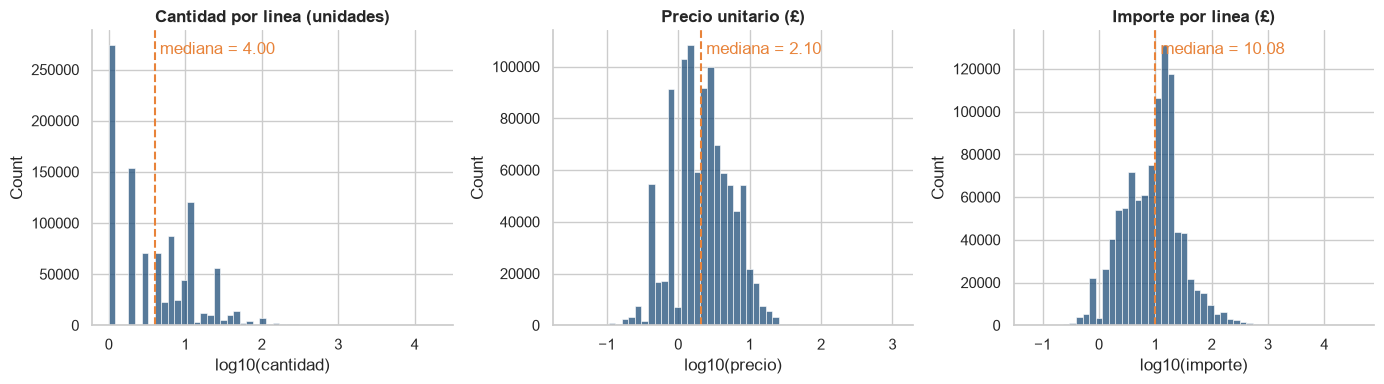

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, tit in zip(axs, ['cantidad', 'precio', 'importe'],
                        ['Cantidad por linea (unidades)', 'Precio unitario (£)', 'Importe por linea (£)']):
    sns.histplot(np.log10(ventas[col]), bins=50, color=AZUL, ax=ax)
    ax.set_xlabel(f'log10({col})'); ax.set_title(tit)
    mediana = np.log10(ventas[col].median())
    ax.axvline(mediana, color=NARANJA, ls='--')
    ax.text(mediana, ax.get_ylim()[1] * .92, f' mediana = {ventas[col].median():,.2f}', color=NARANJA)
plt.tight_layout()
plt.savefig(FIG / '03_distribuciones_numericas.png', dpi=150, bbox_inches='tight')
plt.show()

**Qué muestran las tres distribuciones:**
- Las tres variables tienen **colas larguísimas** (asimetría de 41 a 161): la mediana de una línea es de **4 unidades, £2,10 de precio y £10 de importe**, pero el máximo llega a 19.152 unidades y £38.970.
- Por eso en el resto del proyecto se reportan **medianas** además de promedios y se usan **escalas logarítmicas**: el promedio (£19 por línea) es casi el doble de la mediana (£10).
- En escala log `precio` e `importe` se ven casi simétricos, lo que justifica trabajar con el logaritmo en las pruebas de hipótesis. `cantidad` sigue concentrada en valores bajos (muchas líneas de 1 a 3 unidades, porque son enteros), pero con una cola mucho más corta que en escala normal.

## 2. A nivel de pedido

Un pedido es la unidad con la que el negocio piensa (ticket, devoluciones, recompra). Se resumen sus tres magnitudes: líneas por pedido, unidades y valor.

In [5]:
pedidos[['lineas', 'productos', 'unidades', 'importe']].describe(percentiles=[.5, .9, .99]).T

,count,mean,std,min,50%,90%,99%,max
lineas,"39,514.00",25.39,42.62,1.00,15.00,52.00,198.00,"1,113.00"
productos,"39,514.00",25.11,42.28,1.00,15.00,51.00,196.87,"1,109.00"
unidades,"39,514.00",279.22,"1,070.74",1.00,148.00,523.00,"2,223.61","87,167.00"
importe,"39,514.00",490.96,"1,126.90",0.19,301.21,905.49,"4,097.99","52,940.94"


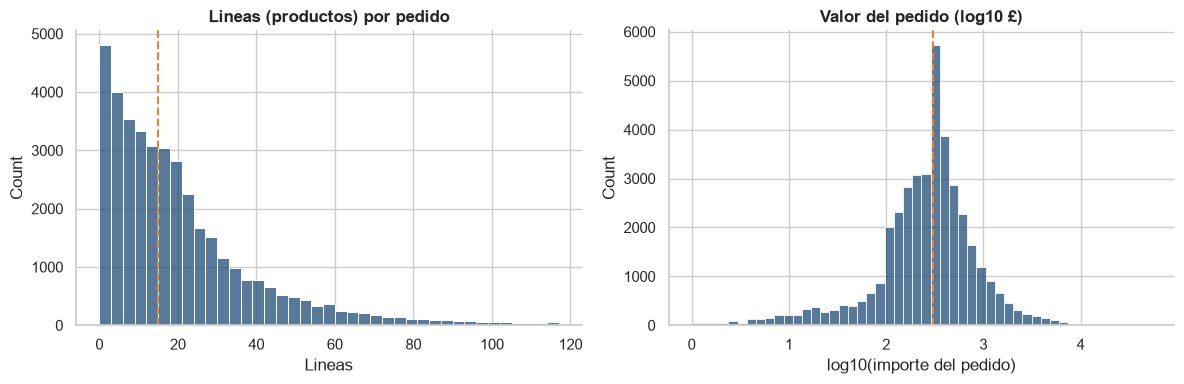

Pedido mediano: 15 lineas y £301  |  pedido promedio: £491


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(pedidos['lineas'], bins=range(0, 120, 3), color=AZUL, ax=axs[0])
axs[0].set_title('Lineas (productos) por pedido'); axs[0].set_xlabel('Lineas')
sns.histplot(np.log10(pedidos['importe'].clip(lower=1)), bins=50, color=AZUL, ax=axs[1])
axs[1].set_title('Valor del pedido (log10 £)'); axs[1].set_xlabel('log10(importe del pedido)')
for ax, v in zip(axs, [pedidos['lineas'].median(), np.log10(pedidos['importe'].median())]):
    ax.axvline(v, color=NARANJA, ls='--')
plt.tight_layout()
plt.show()
print(f'Pedido mediano: {pedidos["lineas"].median():.0f} lineas y £{pedidos["importe"].median():,.0f}  |  pedido promedio: £{pedidos["importe"].mean():,.0f}')

**El pedido típico** tiene 15 líneas y vale **£301** (mediana). El promedio es **£491**: unos pocos pedidos grandes (el 1 % más grande pasa de £4.098) jalan el promedio hacia arriba. Esto confirma que en este negocio **el promedio engaña**: para hablar de un pedido "típico" hay que usar la mediana.